# EDA and data profiling — Final Delivery
**Project:** Domestic violence in Colombia (Policía Nacional – DIJIN) + Comisarías de Familia (MinJusticia SODA API)

This notebook explores **both raw sources exactly as the pipeline extracts them** (`data/raw/`), documents the
quality problems found, and shows how each finding became a transformation (`src/transform_and_integrate.py`)
or a Great Expectations rule (`gx/expectations/*.json`). It also profiles the loaded Data Warehouse and
explains why part of the problem needs a low-latency (streaming) view.

Run it after the batch pipeline (the raw files are created by the `extract_*` tasks). Figures are saved to `docs/img/`.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
IMG = "../docs/img"; os.makedirs(IMG, exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(f"{IMG}/{name}.png", dpi=130); plt.show()

RAW_CSV = "../data/raw/Reporte_Delito_Violencia_Intrafamiliar_Policía_Nacional_20260902.csv"
RAW_API = "../data/raw/api_comisarias_raw.json"
dijin = pd.read_csv(RAW_CSV, dtype=str)            # all text: keeps DANE leading zeros
api = pd.DataFrame(json.load(open(RAW_API, encoding="utf-8")))
print("DIJIN:", dijin.shape, "| API:", api.shape)

DIJIN: (704551, 8) | API: (1249, 15)


## 1. Primary source — DIJIN domestic-violence reports (static dataset)
### 1.1 Structure, nulls and duplicates

In [2]:
profile = pd.DataFrame({
    "dtype": dijin.dtypes.astype(str),
    "nulls": dijin.isna().sum(),
    "null_%": (dijin.isna().mean() * 100).round(3),
    "distinct": dijin.nunique(),
    "example": dijin.iloc[0],
})
print("Exact duplicate rows:", dijin.duplicated().sum())
profile

Exact duplicate rows: 0


,dtype,nulls,null_%,distinct,example
DEPARTAMENTO,str,0,0.000,33,BOYACÁ
MUNICIPIO,str,5,0.001,1021,San Mateo
CODIGO DANE,str,0,0.000,2397,15673000
ARMAS MEDIOS,str,0,0.000,9,SIN EMPLEO DE ARMAS
FECHA HECHO,str,0,0.000,6056,01/03/2026
GENERO,str,3379,0.480,3,FEMENINO
GRUPO ETARIO,str,1406,0.200,3,ADULTOS
CANTIDAD,str,0,0.000,153,1


### 1.2 Measure `CANTIDAD` (victims per record)

count    704551.00
mean          2.13
std           5.38
min           1.00
25%           1.00
50%           1.00
75%           2.00
max         198.00
Name: CANTIDAD_N, dtype: float64
Non-numeric or < 1: 0
Total victims: 1501809


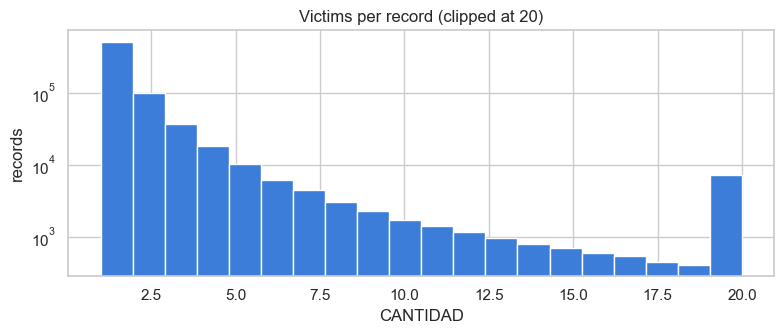

In [3]:
dijin["CANTIDAD_N"] = pd.to_numeric(dijin["CANTIDAD"], errors="coerce")
print(dijin["CANTIDAD_N"].describe().round(2))
print("Non-numeric or < 1:", (dijin["CANTIDAD_N"].isna() | (dijin["CANTIDAD_N"] < 1)).sum())
print("Total victims:", int(dijin["CANTIDAD_N"].sum()))
fig, ax = plt.subplots(figsize=(8, 3.5))
dijin["CANTIDAD_N"].clip(upper=20).plot.hist(bins=20, ax=ax, color="#3b7dd8")
ax.set(title="Victims per record (clipped at 20)", xlabel="CANTIDAD", ylabel="records"); ax.set_yscale("log")
save(fig, "eda_cantidad_hist")

**Finding P1.** `CANTIDAD` is always ≥ 1 but heavily right-skewed (median 1, max 198): a record is an aggregated
report, not a single victim. → The fact table measures **victims** (`cantidad_victimas`) and **records**
(`numero_registros`) separately, and GX rule **DQ-RAW1-04** (critical) requires a numeric value ≥ 1.

### 1.3 Time coverage

Unparseable dates: 0 | range: 2010-01-01 -> 2026-07-31


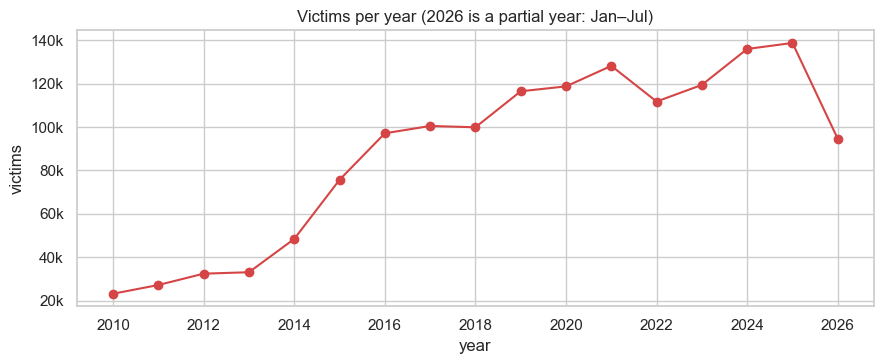

fecha,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
victims,23171,27194,32417,33076,48442,75702,97143,100524,99914,116523,118776,128231,111786,119466,136033,138803,94608


In [4]:
dijin["fecha"] = pd.to_datetime(dijin["FECHA HECHO"], format="%d/%m/%Y", errors="coerce")
print("Unparseable dates:", dijin["fecha"].isna().sum(), "| range:", dijin["fecha"].min().date(), "->", dijin["fecha"].max().date())
yearly = dijin.groupby(dijin["fecha"].dt.year)["CANTIDAD_N"].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
yearly.plot(marker="o", ax=ax, color="#d64545")
ax.set(title="Victims per year (2026 is a partial year: Jan–Jul)", xlabel="year", ylabel="victims")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
save(fig, "eda_victimas_por_anio")
yearly.to_frame("victims").T

**Finding P2.** All dates parse with `dd/mm/yyyy`; coverage is 2010-01-01 → 2026-07-31, so **2026 is incomplete**.
→ GX **DQ-RAW1-02** (critical) enforces the date pattern; `dim_tiempo.es_periodo_completo` flags partial periods so
the BI dashboard never compares 7 months of 2026 against full years.

### 1.4 Geography: DANE codes

In [5]:
print("CODIGO DANE length:", dijin["CODIGO DANE"].str.len().value_counts().to_dict())
mun5 = dijin["CODIGO DANE"].str[:5]
print("Suffix of the 8-digit code:", dijin["CODIGO DANE"].str[5:].value_counts().head(3).to_dict())
print("Invalid municipality codes:", mun5[mun5.isin(["00000", "52000"])].value_counts().to_dict())
print("Distinct 5-digit municipalities:", mun5.nunique())
ct = dijin["MUNICIPIO"].str.contains(r"\(CT\)", na=False)
print("Rows flagged as department capital '(CT)':", int(ct.sum()))
names_per_code = dijin.assign(m=mun5).groupby("m")["MUNICIPIO"].nunique()
print("Codes with more than one spelling of the name:", int((names_per_code > 1).sum()))

CODIGO DANE length: {8: 704551}
Suffix of the 8-digit code: {'000': 696995, '001': 1721, '005': 737}
Invalid municipality codes: {'52000': 5, '00000': 1}
Distinct 5-digit municipalities: 1112
Rows flagged as department capital '(CT)': 274631
Codes with more than one spelling of the name: 1


**Finding P3.** The DANE code always has 8 digits (5-digit municipality + 3-digit populated-centre suffix, `000` in 99 %
of rows), 6 rows use invalid municipality codes (`00000`, `52000`), 39 % of rows carry a `(CT)` department-capital marker
inside the name, and one code appears with two different spellings.
→ Transformation keeps the first 5 digits (`DDMMM`, the API key), remaps `00000`→`05001` and `52000`→`52999`,
derives `es_capital` from `(CT)` and uses the modal name per code. GX **DQ-RAW1-03** (critical) checks the 8-digit length.

### 1.5 Aggression mechanism

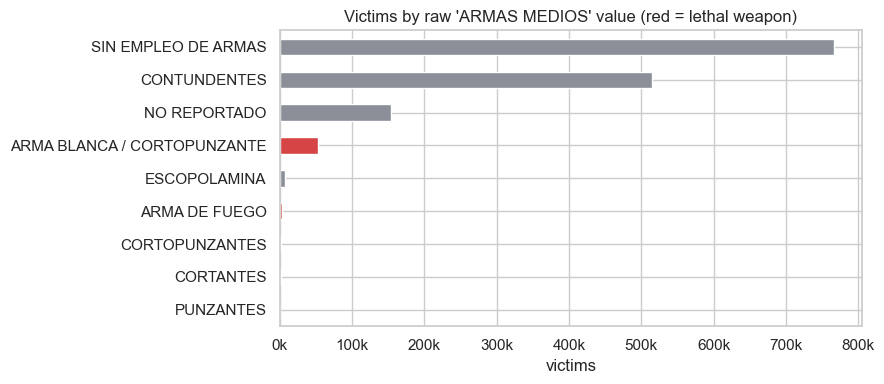

,% victims
ARMAS MEDIOS,
SIN EMPLEO DE ARMAS,51.06
CONTUNDENTES,34.31
NO REPORTADO,10.25
ARMA BLANCA / CORTOPUNZANTE,3.49
ESCOPOLAMINA,0.49
ARMA DE FUEGO,0.22
CORTANTES,0.08
CORTOPUNZANTES,0.08
PUNZANTES,0.02


In [6]:
armas = dijin.groupby("ARMAS MEDIOS")["CANTIDAD_N"].sum().sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
armas.plot.barh(ax=ax, color=["#d64545" if any(k in i for k in ("FUEGO", "BLANCA", "CORTO", "PUNZ", "CORTANTES")) else "#8a8f98" for i in armas.index])
ax.set(title="Victims by raw 'ARMAS MEDIOS' value (red = lethal weapon)", xlabel="victims", ylabel="")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:.0f}k")
save(fig, "eda_armas_medios")
(armas / armas.sum() * 100).round(2).sort_values(ascending=False).to_frame("% victims")

**Finding P4.** Bladed weapons appear under four labels (`ARMA BLANCA / CORTOPUNZANTE`, `CORTOPUNZANTES`, `CORTANTES`,
`PUNZANTES`) and 10.3 % of victims have `NO REPORTADO`. → Labels are harmonised to `ARMA BLANCA`, grouped into
`categoria_mecanismo`, and `es_arma_letal = True` only for bladed weapons and firearms (`dim_medio`). `NO REPORTADO`
is kept as an explicit member instead of being imputed.

### 1.6 Victim demographics

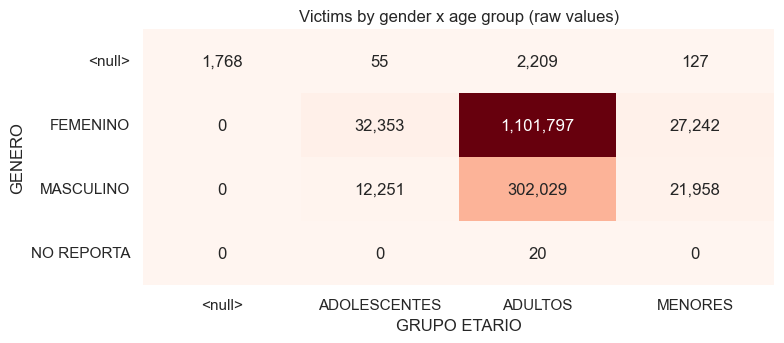

GRUPO,<null>,ADOLESCENTES,ADULTOS,MENORES
GENERO,,,,
<null>,1768,55,2209,127
FEMENINO,0,32353,1101797,27242
MASCULINO,0,12251,302029,21958
NO REPORTA,0,0,20,0


In [7]:
demo = dijin.assign(GENERO=dijin["GENERO"].fillna("<null>"), GRUPO=dijin["GRUPO ETARIO"].fillna("<null>")) \
            .pivot_table(index="GENERO", columns="GRUPO", values="CANTIDAD_N", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.heatmap(demo, annot=True, fmt=",.0f", cmap="Reds", cbar=False, ax=ax)
ax.set(title="Victims by gender x age group (raw values)", xlabel="GRUPO ETARIO", ylabel="GENERO")
save(fig, "eda_demografia")
demo

**Finding P5.** Women are ~3 of every 4 victims; `GENERO` has 3,379 nulls (0.48 %), `GRUPO ETARIO` 1,406 nulls and a
separate `NO REPORTA` value. → Nulls become an explicit `NO REPORTADO` cohort (no victim is dropped, so totals reconcile),
`es_menor_de_edad` is derived for `MENORES`/`ADOLESCENTES`, and GX **DQ-RAW1-05** (warning) tolerates ≤ 1 % null gender.

## 2. Dynamic source — Comisarías de Familia (SODA REST API)

In [8]:
api_profile = pd.DataFrame({
    "nulls_or_'Null'": api.isna().sum() + (api == "Null").sum(),
    "distinct": api.nunique(),
    "example": api.iloc[0],
})
print("Records:", len(api), "| distinct municipality codes:", api["c_digo_dane_municipio"].nunique())
print("Municipality code length:", api["c_digo_dane_municipio"].str.len().value_counts().to_dict())
api_profile

Records: 1249 | distinct municipality codes: 1102
Municipality code length: {5: 1055, 4: 194}


,nulls_or_'Null',distinct,example
c_digo_dane_departamento,0,33,5
nombre,0,33,ANTIOQUIA
c_digo_dane_municipio,0,1102,5088
nombre_1,0,1021,BELLO
tipo_municipio_isla_rea_no,0,1,Municipio
categoria_municipio,17,6,1
comisarias_ley_2126_100_000,115,8,6
existencia_de_comisarias,106,7,1
nombre_comisaria,3,1016,Comisaría Cuarta
direcci_n_comisara,11,1222,Calle 20D # 42A-65


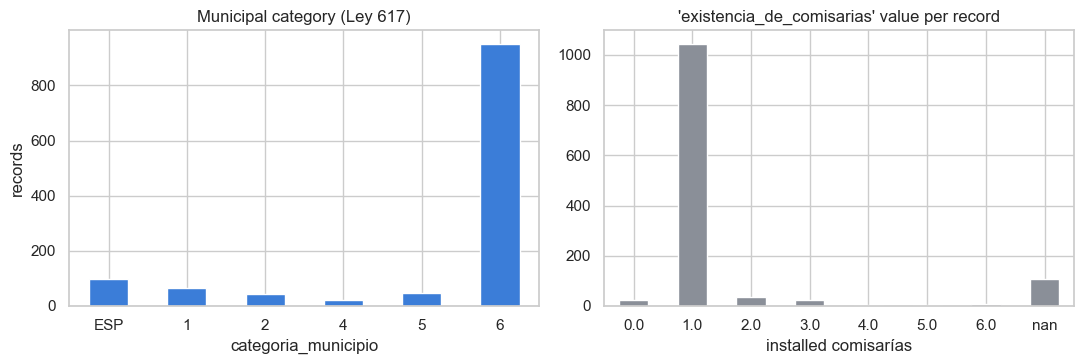

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
api["categoria_municipio"].value_counts().reindex(["ESP", "1", "2", "3", "4", "5", "6"]).dropna() \
    .plot.bar(ax=axes[0], color="#3b7dd8", rot=0, title="Municipal category (Ley 617)")
pd.to_numeric(api["existencia_de_comisarias"], errors="coerce").value_counts(dropna=False).sort_index() \
    .plot.bar(ax=axes[1], color="#8a8f98", rot=0, title="'existencia_de_comisarias' value per record")
axes[0].set(ylabel="records"); axes[1].set(xlabel="installed comisarías")
save(fig, "eda_api_categorias")

**Finding A1.** 194 of 1,249 records lose the leading zero of the DANE code (`5088` instead of `05088`) because the API
types it as a number. → Codes are left-padded to 5 digits before the join; GX **DQ-RAW2-02** (critical) accepts only 4–5 digits.

**Finding A2.** The API is at *comisaría* grain (1,249 rows, 1,102 municipalities), carries the literal string `'Null'` in
contact fields and 24 records report 0 installed comisarías. → `dim_comisaria` keeps the directory (outrigger), the
municipality roll-up computes `comisarias_instaladas`, `comisarias_requeridas_ley` and `brecha_comisarias`; GX
**DQ-RAW2-01** (critical) requires the columns used for the gap and **DQ-RAW2-04** (critical) forbids negative counts.
This is the column removed in the controlled-failure test (Test B).

## 3. Cross-source integration

In [10]:
dij_codes = set(mun5.replace({"00000": "05001", "52000": "52999"}))
api_codes = set(api["c_digo_dane_municipio"].str.zfill(5))
inter = dij_codes & api_codes
print(f"DIJIN municipalities: {len(dij_codes)} | API municipalities: {len(api_codes)}")
print(f"Matched: {len(inter)} ({len(inter)/len(dij_codes):.1%} of DIJIN) | only DIJIN: {len(dij_codes-api_codes)} | only API: {len(api_codes-dij_codes)}")
victims_matched = dijin.loc[mun5.replace({"00000": "05001", "52000": "52999"}).isin(api_codes), "CANTIDAD_N"].sum()
print(f"Victims in matched municipalities: {victims_matched/dijin['CANTIDAD_N'].sum():.2%}")

DIJIN municipalities: 1111 | API municipalities: 1102
Matched: 1100 (99.0% of DIJIN) | only DIJIN: 11 | only API: 2
Victims in matched municipalities: 99.85%


**Finding I1.** After padding, almost every DIJIN municipality matches the API and they hold practically all victims;
the few unmatched codes are non-municipalised areas. → Full outer join on the 5-digit code; unmatched municipalities get
explicit defaults (0 installed comisarías) and GX **DQ-PREP-06** (warning) monitors them.

## 4. Profile of the loaded Data Warehouse (post-ETL)

In [11]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from dotenv import load_dotenv
load_dotenv("../.env")
eng = create_engine(URL.create("postgresql+psycopg2", username=os.getenv("DB_USER", "postgres"),
                               password=os.getenv("DB_PASSWORD"), host=os.getenv("DB_HOST", "localhost"),
                               port=int(os.getenv("DB_PORT", "5432")), database=os.getenv("DB_NAME", "etl_dw")))
counts = pd.read_sql("""
    SELECT 'fact_violencia_intrafamiliar' AS tabla, count(*) AS filas, sum(cantidad_victimas) AS victimas FROM fact_violencia_intrafamiliar
    UNION ALL SELECT 'dim_tiempo', count(*), NULL FROM dim_tiempo
    UNION ALL SELECT 'dim_geografia', count(*), NULL FROM dim_geografia
    UNION ALL SELECT 'dim_victima', count(*), NULL FROM dim_victima
    UNION ALL SELECT 'dim_medio', count(*), NULL FROM dim_medio
    UNION ALL SELECT 'dim_comisaria', count(*), NULL FROM dim_comisaria""", eng)
counts

,tabla,filas,victimas
0,fact_violencia_intrafamiliar,701714,1501809.0
1,dim_tiempo,6056,NaN
2,dim_geografia,1113,NaN
3,dim_victima,11,NaN
4,dim_medio,6,NaN
5,dim_comisaria,1247,NaN


           count   mean    std   min    25%    50%    75%    max
fact_rows  365.0  154.0   32.9   8.0  138.0  151.0  167.0  308.0
victimas   365.0  380.3  101.8  11.0  324.0  375.0  433.0  813.0


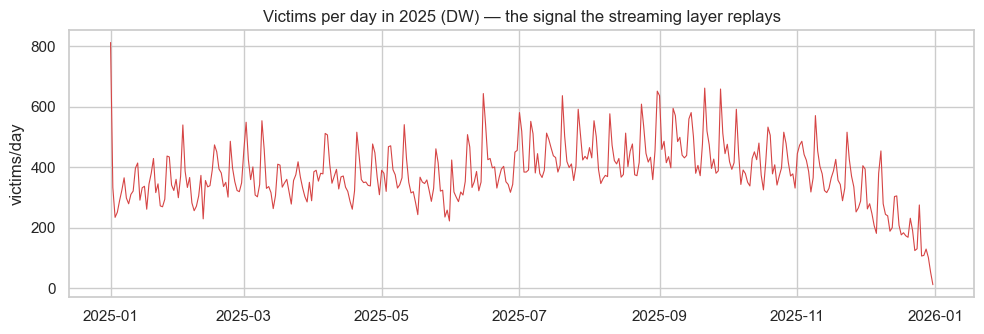

In [12]:
daily = pd.read_sql("""
    SELECT t.fecha, count(*) AS fact_rows, sum(f.cantidad_victimas) AS victimas
    FROM fact_violencia_intrafamiliar f JOIN dim_tiempo t USING (id_tiempo)
    WHERE t.anio = 2025 GROUP BY t.fecha ORDER BY t.fecha""", eng)
print(daily[["fact_rows", "victimas"]].describe().round(1).T)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(daily["fecha"], daily["victimas"], color="#d64545", lw=0.8)
ax.set(title="Victims per day in 2025 (DW) — the signal the streaming layer replays", ylabel="victims/day")
save(fig, "eda_victimas_diarias_2025")

**Finding S1 (why streaming).** In 2025 the DW holds ~150 fact rows and ~380 victims **per day**, with strong
day-to-day peaks (weekends and holidays). A daily batch only reveals a surge in a municipality with a comisaría deficit
the next day; an operational monitoring room needs it within seconds. → The streaming layer replays these fact rows
in chronological order as events (simulation) and maintains live volume, severity and institutional-pressure metrics.

## 5. From findings to pipeline decisions

| # | Finding | Decision / implementation | Quality rule |
|---|---|---|---|
| P1 | `CANTIDAD` aggregated, skewed, always ≥ 1 | Two measures: `cantidad_victimas`, `numero_registros`; fact grain (day, municipality, cohort, mechanism) | DQ-RAW1-04 (critical), DQ-PREP-05 reconciliation (critical) |
| P2 | Dates `dd/mm/yyyy`, 2026 partial | Strict parse; `dim_tiempo.es_periodo_completo` | DQ-RAW1-02 (critical) |
| P3 | 8-digit DANE, invalid `00000`/`52000`, `(CT)`, multiple spellings | Roll-up to 5 digits, remap invalid codes, `es_capital`, modal name | DQ-RAW1-03 (critical) |
| P4 | 4 labels for bladed weapons, `NO REPORTADO` | Harmonised `medio_agresion`, `categoria_mecanismo`, `es_arma_letal` | DQ-PREP-03 (FK integrity) |
| P5 | Null gender / age group | Explicit `NO REPORTADO` cohort, `es_menor_de_edad` | DQ-RAW1-05 (warning) |
| A1 | API codes lose leading zero | `zfill(5)` before join | DQ-RAW2-02 (critical) |
| A2 | Comisaría grain, `'Null'` strings, 0 counts | `dim_comisaria` outrigger; Ley 2126 gap in `dim_geografia` | DQ-RAW2-01, DQ-RAW2-04 (critical) |
| I1 | Near-total match after padding | Outer join + explicit defaults | DQ-PREP-06 (warning) |
| S1 | ~150 fact rows/day with peaks | Streaming replay + 3 live metrics | Event contract v2 + DLQ |
